In [260]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.sparse import diags
from scipy.sparse.linalg import splu
from scipy.stats import norm


In [261]:
from cycler import cycler

plt.rcParams.update({
    "figure.facecolor": "#242424",
    "axes.facecolor": "#303030",
    "axes.edgecolor": "#E6E6E6",
    "axes.labelcolor": "#FFFFFF",
    "axes.titlecolor": "#FFFFFF",
    "xtick.color": "#FFFFFF",
    "ytick.color": "#FFFFFF",
    "text.color": "#FFFFFF",

    "grid.color": "#A8A8A8",
    "grid.alpha": 0.55,
    "grid.linewidth": 0.8,

    "legend.facecolor": "#404040",
    "legend.edgecolor": "#D0D0D0",
    "legend.labelcolor": "#FFFFFF",

    "lines.linewidth": 2.2,
    "axes.prop_cycle": cycler("color", [
        "#00D4FF",  # cyan
        "#FF4D6D",  # pink-red
        "#FFD166",  # yellow
        "#06D6A0",  # green
        "#B983FF",  # violet
        "#FF8C42",  # orange
    ]),

    "savefig.facecolor": "#242424",
})

In [262]:
C = 1.0
S0 = 14
K = 15
r = 0.1
sigma = 0.25
T = 0.5
gamma = 1
s_max = 4*K

https://www.quantpie.co.uk/bsm_bin_c_formula/bs_bin_c_summary.php

In [263]:

def binary_call_analytic(S, K, T, r, sigma, C=1.0):
    d2 = (np.log(S / K) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return C * np.exp(-r * T) * norm.cdf(d2)

def binary_call_delta_analytic(S, K, T, r, sigma, C=1.0):
    d2 = (np.log(S / K) + (r - 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    return C * np.exp(-r * T) * norm.pdf(d2) / (S * sigma * np.sqrt(T))

analytic_value = binary_call_analytic(S0, K, T, r, sigma, C)
analytic_delta = binary_call_delta_analytic(S0, K, T, r, sigma, C)
print(f'Analytic value: {analytic_value:.10f}')
print(f'Analytic Delta: {analytic_delta:.10f}')

Analytic value: 0.4017729576
Analytic Delta: 0.1504232542


In [264]:
def implicit_price(M, N, gamma=1, delta=False, full=False):
    sm = np.linspace(0, s_max, M)
    tn = np.linspace(0, T, N)
    dt = T/(N-1)
    ds = s_max/(M-1)
    a = r*sm[1:-1]/(2*ds)
    b = (sigma**2)/2*(sm[1:-1]**(2*gamma))/(ds**2)
    
    upper = -dt * (a[:-1] + b[:-1])
    lower = -dt * (-a[1:] + b[1:])
    main = 1 + dt * (2 * b + r)

    A = diags([upper, main, lower], [1, 0, -1], format="csc")
    lu = splu(A)  # factorise once, reuse every step
    boundary_values = C * np.exp(-r * (T - tn))
    boundary_coefficient = dt * (a[-1] + b[-1])
    payoff = np.where(sm >= K, C, 0).astype(float)
   
    if not full:
        v = payoff.copy()
        for n in reversed(range(1, N)):
            rhs = v[1:-1].copy()
            rhs[-1] += boundary_coefficient * boundary_values[n - 1]
            v[1:-1] = lu.solve(rhs)
            
        if delta:
            delta_grid = np.gradient(v, sm)
            return np.interp(S0, sm, delta_grid)
        else:
            return np.interp(S0, sm, v)
    else:
        vg = np.zeros((N, M))
        vg[:, -1] = boundary_values
        vg[-1, :] = payoff

        for n in reversed(range(1, N)):
            rhs = vg[n, 1:-1].copy()
            rhs[-1] += boundary_coefficient * boundary_values[n - 1]
            vg[n - 1, 1:-1] = lu.solve(rhs)
        sg, tg = np.meshgrid(sm, tn)
        return sg, tg, vg 


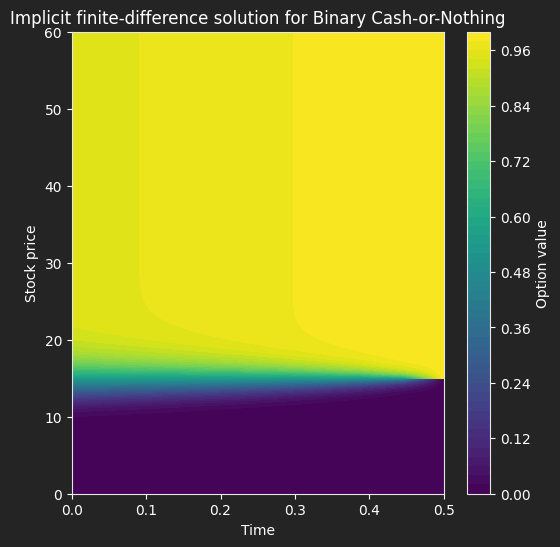

In [265]:
M=10003
N=10
sg, tg, vg = implicit_price(M, N, gamma=1, full=True)
plt.figure(figsize=(6, 6))
contour = plt.contourf(tg, sg, vg, levels=50)
plt.colorbar(contour, label="Option value")
plt.xlabel("Time")
plt.ylabel("Stock price")
plt.title("Implicit finite-difference solution for Binary Cash-or-Nothing")
plt.show()

S -> 0: = 0.0
S -> inf error: = 0.0
Monotone: True
Max out of bound: 3.943822228902327e-06


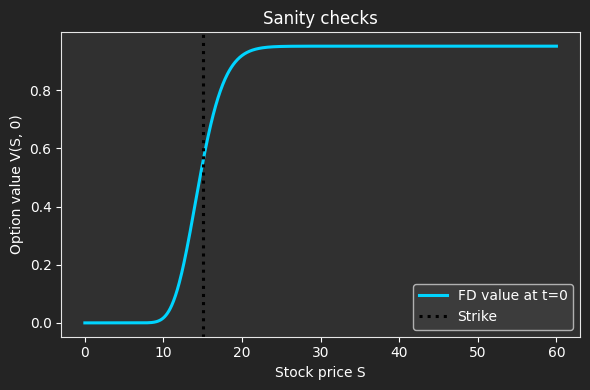

In [266]:
M_check, N_check = 1000, 300
sg, tg, vg = implicit_price(M_check, N_check, gamma=1.0, full=True)

stock = sg[0, :]
value_today = vg[0, :]
discounted_payoff = C * np.exp(-r * (T - tg))

tol = 1e-6
print(f"S -> 0: = {np.max(np.abs(vg[:, 0]))}")
print(f"S -> inf error: = {np.max(np.abs(vg[:, -1])- discounted_payoff[:, -1])}")
print(f'Monotone: {np.all(np.diff(vg, axis=1) >= -tol)}')
print(f'Max out of bound: {max(np.max(-vg), np.max(vg - discounted_payoff))}')

plt.figure(figsize=(6, 4))
plt.plot(stock, value_today, label='FD value at t=0')
plt.axvline(K, color='black', linestyle=':', label='Strike')
plt.xlabel('Stock price S')
plt.ylabel('Option value V(S, 0)')
plt.title('Sanity checks')
plt.legend()
plt.tight_layout()
plt.show()

In [267]:
fd_value = implicit_price(M=20003, N=100000, full=False)
exact_value = binary_call_analytic(S0, K, T, r, sigma, C=1)
error = abs(fd_value - exact_value)
print("FD:", fd_value)
print("Exact:", exact_value)
print("Abs error:", error)

FD: 0.4017722721639318
Exact: 0.40177295755490844
Abs error: 6.853909766402211e-07


In [268]:
# M_values = np.array([50, 100, 200, 400, 800, 1000, 2000, 3000])
# M_values = np.array([K*1, 100, 200, 400, 800, 1000, 2000, 3000])
M_values = np.array([100, 200, 400, 800, 1000, 2000, 3000])
# M_values = M_values + 4 # På 0.75
M_values = M_values + 3 # På 0.5
# M_values = M_values + 2 #På 0.25
# M_values = M_values + 1 #På K

N_for_M = 320000
M_errors = np.array([
    abs(implicit_price(M=m_value, N=N_for_M, full=False) - analytic_value)
    for m_value in M_values
])

print(K*(M_values-1)/s_max) #Int om på K, 0.5 om exakt mellan
p = np.log(M_errors[:-1] / M_errors[1:]) / (np.log(M_values[1:] / M_values[:-1]))
print(p)

M_fit = np.polyfit(np.log(M_values), np.log(M_errors), 1)
M_order = M_fit[0]
M_fit_errors = np.exp(np.polyval(M_fit, np.log(M_values)))



[ 25.5  50.5 100.5 200.5 250.5 500.5 750.5]
[1.87490508 2.08760708 1.94788447 2.07211745 1.91049628 1.87470773]


In [269]:
#Testcell
M_values = np.array([100, 200, 400, 800, 1000, 2000, 3000])
M_values = M_values + 2 #På 0.25
print(K*(M_values-1)/s_max) #Int om på K, 0.5 om exakt mellan


[ 25.25  50.25 100.25 200.25 250.25 500.25 750.25]


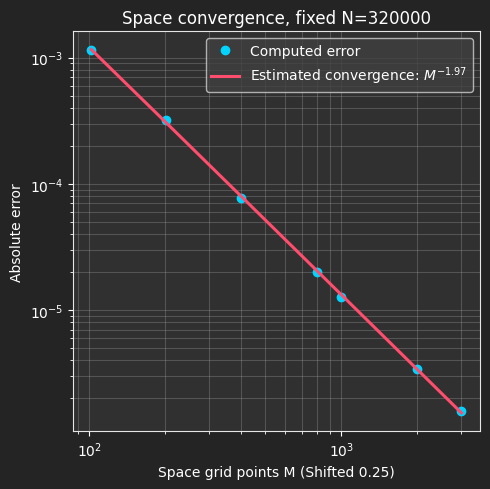

In [270]:
plt.figure(figsize=(5, 5))
plt.loglog(M_values, M_errors, "o", label="Computed error")
plt.loglog(M_values, M_fit_errors,"-", label=fr"Estimated convergence: $M^{{{M_order:.2f}}}$",
)
plt.xlabel(f"Space grid points M (Shifted {(K*(M_values[0]-1)/s_max) % 1})")
plt.ylabel("Absolute error")
plt.title(fr"Space convergence, fixed N={N_for_M}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [271]:
N_values = np.array([25, 50, 100, 200, 400, 800])

M_for_N = 200001
N_errors = np.array([
    abs(implicit_price(M=M_for_N, N=n_value, full=False) - analytic_value)
    for n_value in N_values
])

N_fit = np.polyfit(np.log(N_values), np.log(N_errors), 1)
N_order = N_fit[0]
N_fit_errors = np.exp(np.polyval(N_fit, np.log(N_values)))


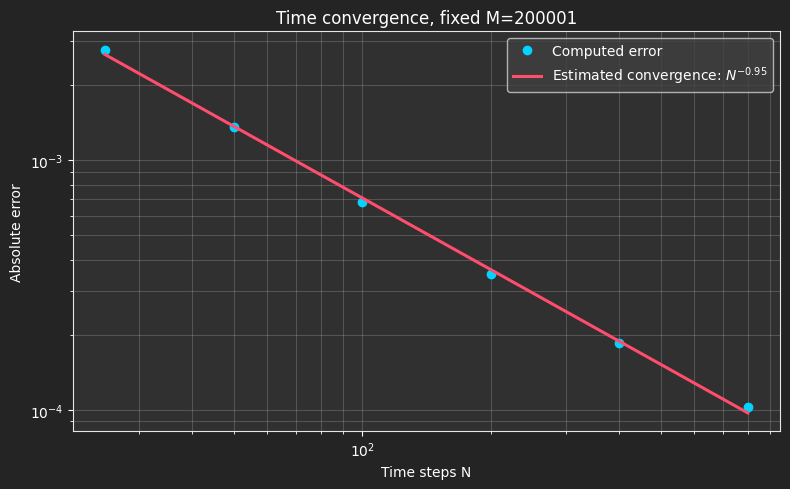

In [272]:
plt.figure(figsize=(8, 5))
plt.loglog(N_values, N_errors, "o", label="Computed error")
plt.loglog( N_values,N_fit_errors,"-", label=fr"Estimated convergence: $N^{{{N_order:.2f}}}$",
)
plt.xlabel("Time steps N")
plt.ylabel("Absolute error")
plt.title(fr"Time convergence, fixed M={M_for_N}")
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

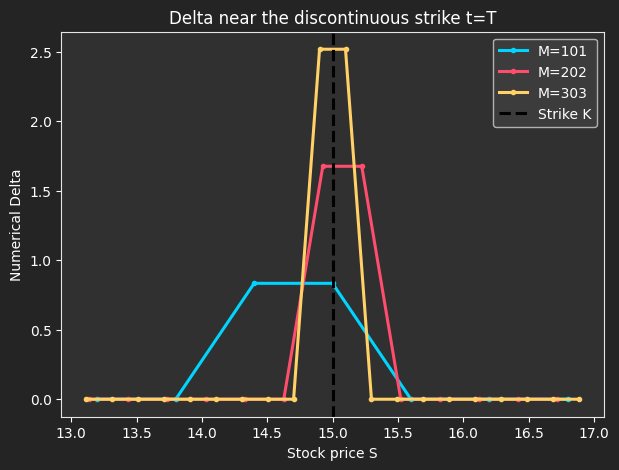

In [273]:
plt.figure(figsize=(7, 5))
for M in [101, 202, 303]:
    stock_grid, _, value_grid = implicit_price(M, 300, full=True)
    stock = stock_grid[0, :]
    value = value_grid[-1, :]
    delta = np.gradient(value, stock)
    near_strike = (stock >= K - 2) & (stock <= K + 2)
    plt.plot(stock[near_strike], delta[near_strike], '.-', label=f'M={M}')
plt.axvline(K, color='black', linestyle='--', label='Strike K')
plt.xlabel('Stock price S')
plt.ylabel('Numerical Delta')
plt.title('Delta near the discontinuous strike t=T')
plt.legend()
plt.show()

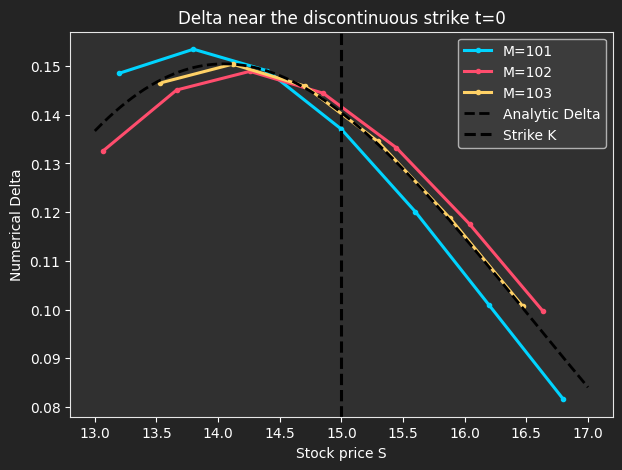

In [274]:
plt.figure(figsize=(7, 5))
for M in [101, 102, 103]:
    stock_grid, _, value_grid = implicit_price(M, 300, full=True)
    stock = stock_grid[0, :]
    value = value_grid[0, :]
    delta = np.gradient(value, stock)
    near_strike = (stock >= K - 2) & (stock <= K + 2)
    plt.plot(stock[near_strike], delta[near_strike], '.-', label=f'M={M}')
    
stock_true = np.linspace(K - 2, K + 2, 500)
true_delta = binary_call_delta_analytic(stock_true, K, T, r, sigma, C)
plt.plot(stock_true, true_delta, "k--", linewidth=2, label="Analytic Delta")
plt.axvline(K, color='black', linestyle='--', label='Strike K')
plt.xlabel('Stock price S')
plt.ylabel('Numerical Delta')
plt.title('Delta near the discontinuous strike t=0')
plt.legend()
plt.show()

In [275]:
# M_delta_values = np.array([50, 100, 200, 400, 800, 1000, 2000, 3000])

# M_delta_values = np.array([1000, 2000, 3000, 4000, 5000])
# M_values = np.array([50, 100, 200, 400, 800, 1000, 2000, 3000])
M_delta_values = np.array([100, 200, 400, 800, 1000, 2000, 3000])
# M_delta_values = M_delta_values + 4 # På 0.75
# M_delta_values = M_delta_values + 3 # På 0.5
# M_delta_values = M_delta_values + 2 #På 0.25
M_delta_values = M_delta_values + 1 #På K

N_for_delta_M = 320000
M_delta_errors = np.array([
    abs(implicit_price(M, N_for_delta_M, delta =True) - analytic_delta)
    for M in M_delta_values
])


print(K*(M_delta_values-1)/s_max) #Int om på K, 0.5 om exakt mellan
p = np.log(M_delta_errors[:-1] / M_delta_errors[1:]) / (np.log(M_delta_values[1:] / M_delta_values[:-1]))
print(p)

M_delta_fit = np.polyfit(np.log(M_delta_values), np.log(M_delta_errors),1)
M_delta_order = M_delta_fit[0]
M_delta_fit_errors = np.exp(np.polyval(M_delta_fit, np.log(M_delta_values)))

[ 25.  50. 100. 200. 250. 500. 750.]
[0.26637086 0.71765854 0.87599013 0.92502708 0.95270799 0.94806773]


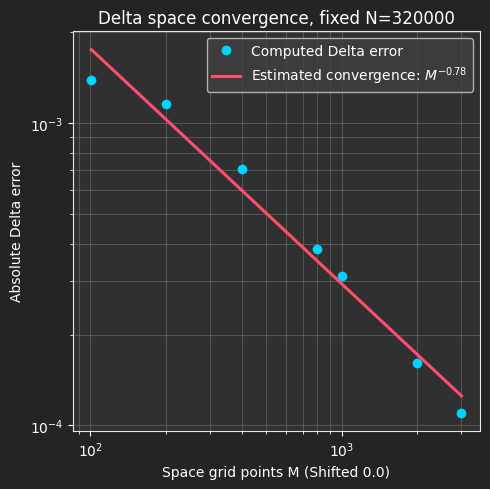

In [276]:
plt.figure(figsize=(5, 5))
plt.loglog(M_delta_values, M_delta_errors, "o", label="Computed Delta error")
plt.loglog(M_delta_values, M_delta_fit_errors,"-", label=fr"Estimated convergence: $M^{{{M_delta_order:.2f}}}$",
)
plt.xlabel(f"Space grid points M (Shifted {(K*(M_delta_values[0]-1)/s_max) % 1})")
plt.ylabel("Absolute Delta error")
plt.title(fr"Delta space convergence, fixed N={N_for_delta_M}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [277]:
N_delta_values = np.array([25, 50, 100, 200, 400, 800])

M_for_delta_N = 80000
N_delta_errors = np.array([
    abs(implicit_price(M_for_delta_N, N, delta=True) - analytic_delta)
    for N in N_delta_values
])

N_delta_fit = np.polyfit(np.log(N_delta_values), np.log(N_delta_errors),1)
N_delta_order = N_delta_fit[0]
N_delta_fit_errors = np.exp(np.polyval(N_delta_fit, np.log(N_delta_values)))

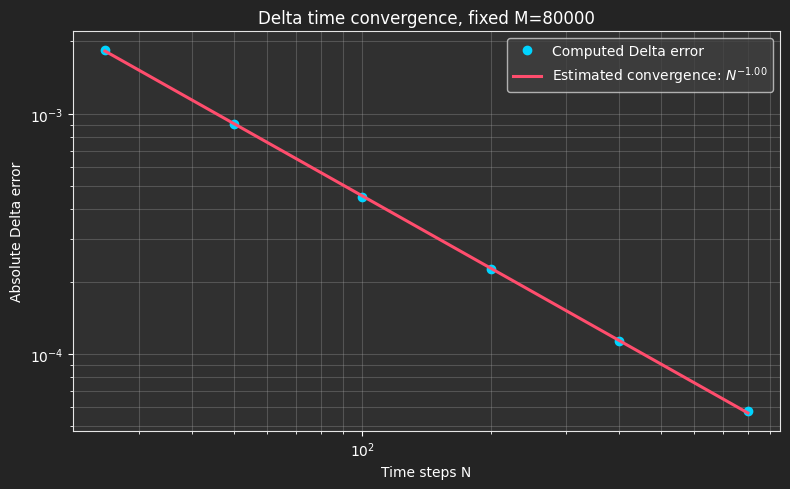

In [278]:
plt.figure(figsize=(8, 5))
plt.loglog(N_delta_values, N_delta_errors, "o", label="Computed Delta error",)
plt.loglog(N_delta_values, N_delta_fit_errors,"-", label=fr"Estimated convergence: $N^{{{N_delta_order:.2f}}}$",)
plt.xlabel("Time steps N")
plt.ylabel("Absolute Delta error")
plt.title(fr"Delta time convergence, fixed M={M_for_delta_N}")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()